## 1.1 Importación de librerías y descarga/carga de datos

In [1]:
import os
import urllib.request
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Definir rutas y URL
DATA_URL = "https://raw.githubusercontent.com/4GeeksAcademy/k-means-project-tutorial/main/housing.csv"
RAW_DATA_PATH = "../data/raw/housing.csv"

# 2. Descargar si no existe localmente
os.makedirs("../data/raw", exist_ok=True)
if not os.path.exists(RAW_DATA_PATH):
    print("Descargando housing.csv...")
    urllib.request.urlretrieve(DATA_URL, RAW_DATA_PATH)
    print("Descarga completada.")

# 3. Cargar en DataFrame
df_raw = pd.read_csv(RAW_DATA_PATH)
df_raw.head()


Descargando housing.csv...
Descarga completada.


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [2]:
# Filtrar únicamente las variables de interés
features = ["Latitude", "Longitude", "MedInc"]
df = df_raw[features].copy()

# Dividir en Train y Test (80% train, 20% test)
X_train, X_test = train_test_split(df, test_size=0.2, random_state=42)

print(f"Dimensiones de Train: {X_train.shape}")
print(f"Dimensiones de Test:  {X_test.shape}")
X_train.describe()


Dimensiones de Train: (16512, 3)
Dimensiones de Test:  (4128, 3)


,Latitude,Longitude,MedInc
count,16512.000000,16512.000000,16512.000000
mean,35.643149,-119.582290,3.880754
std,2.136665,2.005654,1.904294
min,32.550000,-124.350000,0.499900
25%,33.930000,-121.810000,2.566700
50%,34.260000,-118.510000,3.545800
75%,37.720000,-118.010000,4.773175
max,41.950000,-114.310000,15.000100


## 📍 Paso 2: Construcción y entrenamiento del modelo K-Means

### 2.1 Entrenamiento del K-Means y categorización

In [11]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Instanciar y entrenar K-Means con 6 clusters
kmeans = KMeans(n_clusters=6, random_state=42, n_init="auto")
train_clusters = kmeans.fit_predict(X_train)

# 2. Asignar la columna 'cluster' a una copia del conjunto de entrenamiento
X_train_clustered = X_train.copy()
X_train_clustered["cluster"] = train_clusters

# 3. Categorizar la columna cluster
X_train_clustered["cluster"] = X_train_clustered["cluster"].astype("category")

print("Distribución de observaciones por cluster:")
print(X_train_clustered["cluster"].value_counts().sort_index())
X_train_clustered.head()


Distribución de observaciones por cluster:
cluster
0    2455
1    3807
2    1280
3    4368
4     246
5    4356
Name: count, dtype: int64


,Latitude,Longitude,MedInc,cluster
14196,32.71,-117.03,3.2596,3
8267,33.77,-118.16,3.8125,1
17445,34.66,-120.48,4.1563,1
14265,32.69,-117.11,1.9425,3
2271,36.78,-119.80,3.5542,5


### 2.2 Visualización gráfica de los clusters (Train)

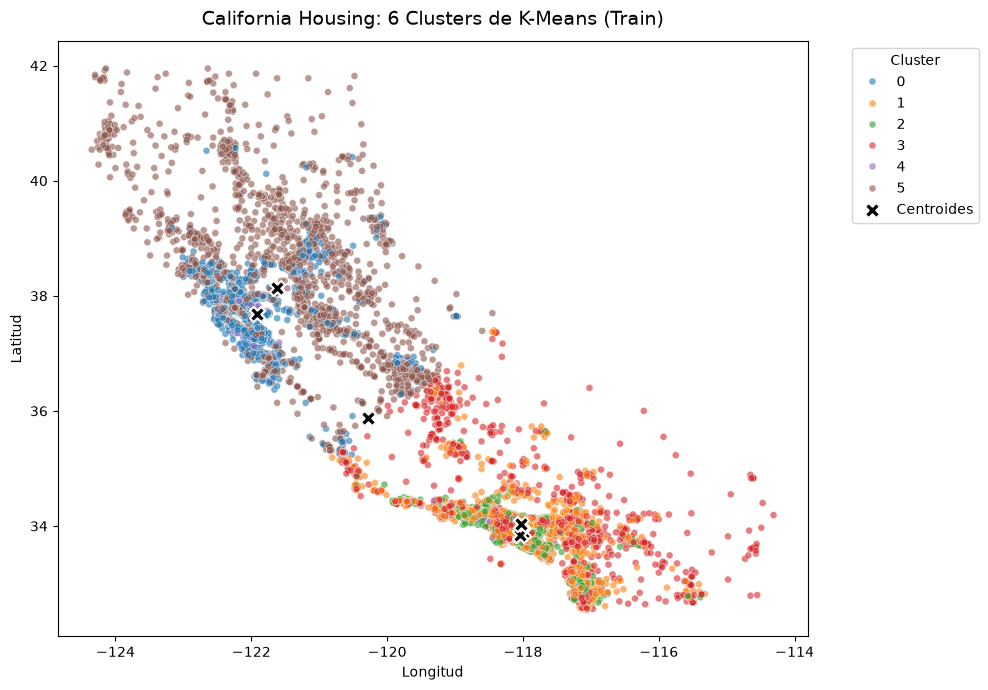

In [12]:
plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=X_train_clustered,
    x="Longitude",
    y="Latitude",
    hue="cluster",
    palette="tab10",
    alpha=0.6,
    s=25
)

# Dibujar los centroides (proyectados en Longitude y Latitude)
centroids = kmeans.cluster_centers_
plt.scatter(
    centroids[:, 1], # Longitude del centroide
    centroids[:, 0], # Latitude del centroide
    c="black",
    s=120,
    marker="X",
    label="Centroides",
    edgecolors="white",
    linewidths=1.5
)

plt.title("California Housing: 6 Clusters de K-Means (Train)", fontsize=14, pad=12)
plt.xlabel("Longitud")
plt.ylabel("Latitud")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", title="Cluster")
plt.tight_layout()
plt.show()


### 2.3 ¿Cómo influye el ingreso medio (MedInc) en cada cluster?

In [5]:
# Estadísticas descriptivas de cada cluster para entender su perfil
cluster_summary = X_train_clustered.groupby("cluster", observed=False).mean()
cluster_summary


,Latitude,Longitude,MedInc
cluster,,,
0,37.686925,-121.915650,5.380158
1,33.889414,-118.002840,4.348026
2,33.849680,-118.041547,6.939476
3,34.041557,-118.024263,2.428376
4,35.878171,-120.284228,11.748734
5,38.143742,-121.623042,2.740572


## 🔍 Paso 3: Predicción con el conjunto de Test y validación gráfica

### 3.1 Predicción en Test y categorización

In [13]:
# 1. Predecir los clusters en el conjunto de prueba
test_clusters = kmeans.predict(X_test)

# 2. Asignar la columna 'cluster' al conjunto de test
X_test_clustered = X_test.copy()
X_test_clustered["cluster"] = test_clusters
X_test_clustered["cluster"] = X_test_clustered["cluster"].astype("category")

print("Distribución de observaciones por cluster en Test:")
print(X_test_clustered["cluster"].value_counts().sort_index())
X_test_clustered.head()


Distribución de observaciones por cluster en Test:
cluster
0     561
1     983
2     299
3    1111
4      62
5    1112
Name: count, dtype: int64


,Latitude,Longitude,MedInc,cluster
20046,36.06,-119.01,1.6812,3
3024,35.14,-119.46,2.5313,3
15663,37.80,-122.44,3.4801,5
20484,34.28,-118.72,5.7376,2
9814,36.62,-121.93,3.7250,5


### 3.2 Visualización superpuesta: Train vs Test

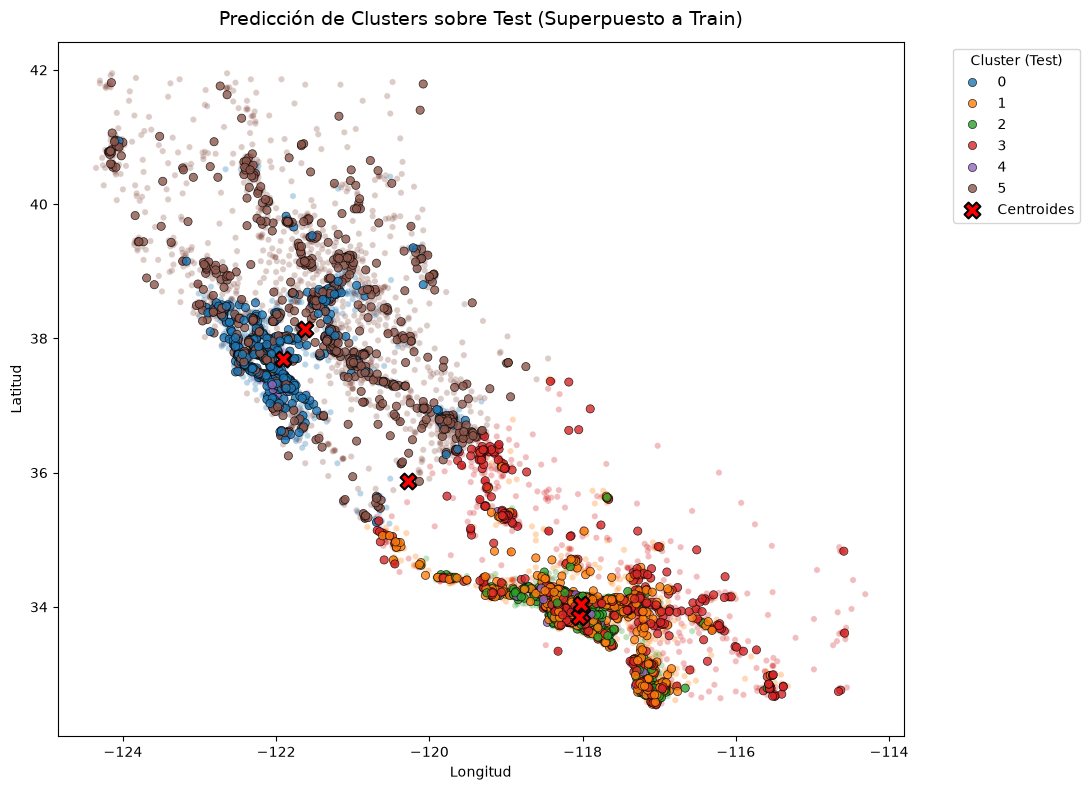

In [14]:
plt.figure(figsize=(11, 8))

# 1. Puntos de entrenamiento (como referencia en el fondo)
sns.scatterplot(
    data=X_train_clustered,
    x="Longitude",
    y="Latitude",
    hue="cluster",
    palette="tab10",
    alpha=0.3,
    s=20,
    legend=False
)

# 2. Puntos de prueba predichos (superpuestos)
sns.scatterplot(
    data=X_test_clustered,
    x="Longitude",
    y="Latitude",
    hue="cluster",
    palette="tab10",
    marker="o",
    edgecolor="black",
    linewidth=0.5,
    alpha=0.8,
    s=35
)

# 3. Centroides calculados por K-Means
plt.scatter(
    centroids[:, 1],
    centroids[:, 0],
    c="red",
    s=130,
    marker="X",
    label="Centroides",
    edgecolors="black",
    linewidths=1.5
)

plt.title("Predicción de Clusters sobre Test (Superpuesto a Train)", fontsize=14, pad=12)
plt.xlabel("Longitud")
plt.ylabel("Latitud")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", title="Cluster (Test)")
plt.tight_layout()
plt.show()


### 3.3 Comparación de medias (Train vs Test)

In [8]:
test_summary = X_test_clustered.groupby("cluster", observed=False).mean()
print("Medias por cluster en TEST:")
display(test_summary)

Medias por cluster en TEST:


,Latitude,Longitude,MedInc
cluster,,,
0,37.705775,-121.958307,5.383123
1,33.874598,-118.007355,4.311094
2,33.797793,-118.009030,6.964829
3,34.011107,-117.968308,2.444694
4,35.435161,-119.837097,11.715661
5,38.094793,-121.563570,2.723911


 ## Paso 4: Entrenamiento de un Modelo de Clasificación Supervisada

### 4.1 Definición de variables $X$, $y$ y entrenamiento del clasificador

In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Definir variables predictoras y variable objetivo
X_tr = X_train[["Latitude", "Longitude", "MedInc"]]
y_tr = X_train_clustered["cluster"]

X_te = X_test[["Latitude", "Longitude", "MedInc"]]
y_te = X_test_clustered["cluster"]

# 2. Instanciar y entrenar Random Forest Classifier
clf_rf = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)
clf_rf.fit(X_tr, y_tr)

# 3. Predicciones en Train y Test
y_pred_train = clf_rf.predict(X_tr)
y_pred_test = clf_rf.predict(X_te)

# 4. Métricas de Accuracy
acc_train = accuracy_score(y_tr, y_pred_train)
acc_test = accuracy_score(y_te, y_pred_test)

print(f"Accuracy en Train: {acc_train:.4f} ({acc_train*100:.2f}%)")
print(f"Accuracy en Test:  {acc_test:.4f} ({acc_test*100:.2f}%)")


Accuracy en Train: 0.9996 (99.96%)
Accuracy en Test:  0.9954 (99.54%)


4.2 Reporte de clasificación y matriz de confusión

--- Classification Report (Test) ---
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       561
           1       0.99      1.00      1.00       983
           2       0.99      1.00      1.00       299
           3       1.00      1.00      1.00      1111
           4       1.00      0.95      0.98        62
           5       1.00      0.99      0.99      1112

    accuracy                           1.00      4128
   macro avg       1.00      0.99      0.99      4128
weighted avg       1.00      1.00      1.00      4128



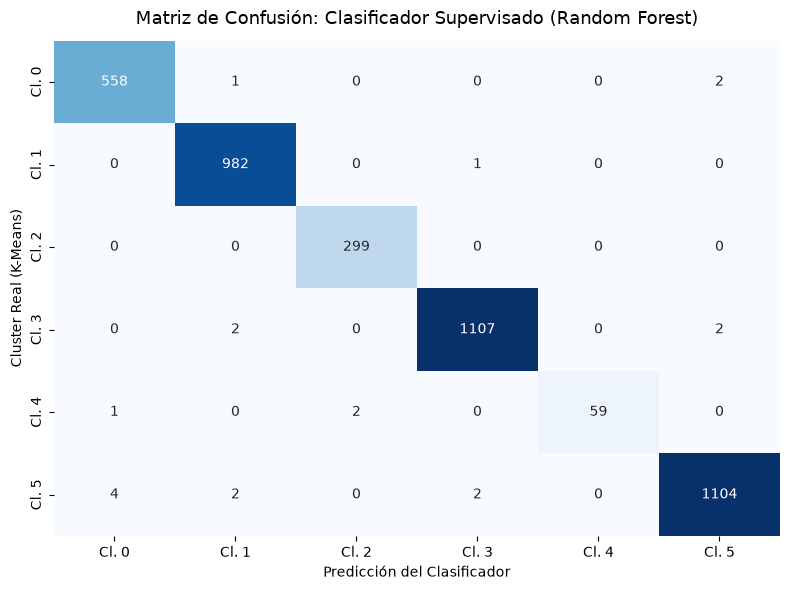

In [ ]:
# Reporte de clasificación por cluster
print("--- Classification Report (Test) ---")
print(classification_report(y_te, y_pred_test))

# Matriz de Confusión
cm = confusion_matrix(y_te, y_pred_test)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=[f"Cl. {i}" for i in range(6)],
            yticklabels=[f"Cl. {i}" for i in range(6)])
plt.title("Matriz de Confusión: Clasificador Supervisado (Random Forest)", fontsize=13, pad=12)
plt.xlabel("Predicción del Clasificador")
plt.ylabel("Cluster Real (K-Means)")
plt.tight_layout()
plt.show()

### 4.3 Importancia de las características

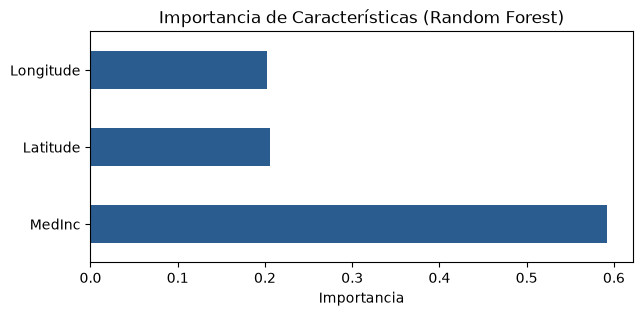

In [15]:
# Importancia de cada variable en el modelo supervisado
feat_importances = pd.Series(clf_rf.feature_importances_, index=X_tr.columns)
feat_importances.sort_values(ascending=False).plot(kind="barh", color="#2b5c8f", figsize=(7, 3))
plt.title("Importancia de Características (Random Forest)")
plt.xlabel("Importancia")
plt.show()


## 💾 Paso 5: Almacenamiento y persistencia de los modelos

### 5.1 Guardado de los modelos en models/

In [16]:
import joblib

# 1. Asegurar la existencia del directorio models y data/processed
os.makedirs("../models", exist_ok=True)
os.makedirs("../data/processed", exist_ok=True)

# 2. Rutas de destino
kmeans_path = "../models/kmeans_clusters_6.joblib"
rf_path = "../models/random_forest_classifier.joblib"

# 3. Guardar ambos modelos
joblib.dump(kmeans, kmeans_path)
joblib.dump(clf_rf, rf_path)

# 4. Guardar los datasets procesados con la columna 'cluster'
X_train_clustered.to_csv("../data/processed/housing_train_clustered.csv", index=False)
X_test_clustered.to_csv("../data/processed/housing_test_clustered.csv", index=False)

print(f"✅ Modelo K-Means guardado en: {kmeans_path}")
print(f"✅ Modelo Supervisado guardado en: {rf_path}")
print(f"✅ Datasets procesados guardados en ../data/processed/")


✅ Modelo K-Means guardado en: ../models/kmeans_clusters_6.joblib
✅ Modelo Supervisado guardado en: ../models/random_forest_classifier.joblib
✅ Datasets procesados guardados en ../data/processed/


### 5.2 Test de carga y verificación de inferencia

In [18]:
# 1. Cargar modelos desde disco
loaded_kmeans = joblib.load(kmeans_path)
loaded_rf = joblib.load(rf_path)

# 2. Punto de prueba ficticio: Latitud 34.05, Longitud -118.25 (Los Ángeles), MedInc 4.5
nuevo_hogar = pd.DataFrame([{
    "Latitude": 34.05,
    "Longitude": -118.25,
    "MedInc": 4.5
}])

pred_cluster_kmeans = loaded_kmeans.predict(nuevo_hogar)[0]
pred_cluster_rf = loaded_rf.predict(nuevo_hogar)[0]

print("--- Verificación de inferencia con modelos guardados ---")
print(f"Cluster asignado por K-Means:         {pred_cluster_kmeans}")
print(f"Cluster predicho por Random Forest:    {pred_cluster_rf}")
print(f"¿Ambos modelos coinciden?:             {pred_cluster_kmeans == pred_cluster_rf}")


--- Verificación de inferencia con modelos guardados ---
Cluster asignado por K-Means:         1
Cluster predicho por Random Forest:    1
¿Ambos modelos coinciden?:             True
